# Production Optimization Using Nodal Analysis

Integrated **IPR-VLP** model for a vertical oil well (field units: psi, bbl/d, scf/stb, ft, in, deg F, cp).

* **Solution node:** bottom-hole (sandface), Pwf
* **Inflow (IPR):** composite linear (Pwf >= Pb) plus Vogel (Pwf < Pb)
* **Outflow (VLP):** pressure traverse wellhead to bottom-hole (drift-flux holdup, friction, Standing / Beggs-Robinson PVT)

The notebook finds the natural-flow operating point, runs sensitivities on water cut, GOR, tubing diameter,
reservoir pressure and wellhead pressure, and ranks the production bottlenecks.

## 0. Imports and constants

In [1]:
%matplotlib inline
import math
from dataclasses import dataclass, replace

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

G = 32.174      # ft/s^2
GC = 32.174     # lbm ft / (lbf s^2)

## 1. Input data

Base-case well. These are illustrative values: edit the `Well` dataclass to use your own field data.

In [2]:
@dataclass(frozen=True)
class Well:
    # Reservoir / IPR
    p_res: float = 3500.0      # psi, average reservoir pressure
    J: float = 2.0             # bpd/psi, liquid PI above bubble point
    # Fluids
    api: float = 35.0
    gas_sg: float = 0.70
    water_sg: float = 1.05
    gor: float = 600.0         # scf/stb (producing GOR = solution GOR)
    wc: float = 0.20           # water cut, fraction of liquid
    # Well / tubing
    depth: float = 8000.0      # ft TVD (vertical well)
    tubing_id: float = 2.992   # in
    roughness: float = 0.00065 # in
    p_wh: float = 200.0        # psi, wellhead (flowing tubing head) pressure
    t_wh: float = 100.0        # deg F
    t_bh: float = 180.0        # deg F


BASE = Well()

## 2. PVT correlations

Standing bubble point, solution GOR and oil FVF; Beggs-Robinson oil viscosity; Papay Z-factor and
Lee-Gonzalez-Eakin gas viscosity.

In [3]:
def bubble_point(w: Well) -> float:
    """Standing bubble-point pressure (psi) for Rs = producing GOR."""
    return 18.2 * ((w.gor / w.gas_sg) ** 0.83
                   * 10 ** (0.00091 * w.t_bh - 0.0125 * w.api) - 1.4)


def pvt(p, T, w: Well, pb):
    """Return dict of fluid properties at pressure p (psi), temperature T (F)."""
    p = max(p, 15.0)
    TR = T + 459.67
    gamma_o = 141.5 / (131.5 + w.api)

    # solution GOR
    if p >= pb:
        rs = w.gor
    else:
        rs = w.gas_sg * ((p / 18.2 + 1.4) * 10 ** (0.0125 * w.api - 0.00091 * T)) ** 1.2048
        rs = min(rs, w.gor)

    # oil FVF (Standing) and undersaturated correction
    pp = min(p, pb)
    rs_b = rs if p < pb else w.gor
    bo = 0.9759 + 0.000120 * (rs_b * math.sqrt(w.gas_sg / gamma_o) + 1.25 * T) ** 1.2
    if p > pb:
        bo *= math.exp(-1.0e-5 * (p - pb))

    # oil density (lb/ft3)
    rho_o = (62.4 * gamma_o + 0.0136 * rs * w.gas_sg) / bo

    # oil viscosity (Beggs-Robinson)
    x = 10 ** (3.0324 - 0.02023 * w.api) * T ** -1.163
    mu_od = 10 ** x - 1
    a = 10.715 * (rs + 100) ** -0.515
    b = 5.44 * (rs + 150) ** -0.338
    mu_o = a * mu_od ** b

    # gas Z (Papay), density, FVF, viscosity (Lee-Gonzalez-Eakin)
    tpc = 168 + 325 * w.gas_sg - 12.5 * w.gas_sg ** 2
    ppc = 677 + 15 * w.gas_sg - 37.5 * w.gas_sg ** 2
    ppr, tpr = p / ppc, TR / tpc
    z = 1 - 3.52 * ppr / 10 ** (0.9813 * tpr) + 0.274 * ppr ** 2 / 10 ** (0.8157 * tpr)
    z = max(z, 0.3)
    bg = 0.02827 * z * TR / p                       # ft3/scf
    rho_g = 2.7 * w.gas_sg * p / (z * TR)           # lb/ft3
    M = 28.97 * w.gas_sg
    K = (9.4 + 0.02 * M) * TR ** 1.5 / (209 + 19 * M + TR)
    X = 3.5 + 986 / TR + 0.01 * M
    Y = 2.4 - 0.2 * X
    mu_g = 1e-4 * K * math.exp(X * (rho_g / 62.428) ** Y)

    rho_w = 62.4 * w.water_sg / 1.02
    return dict(rs=rs, bo=bo, rho_o=rho_o, mu_o=mu_o, bg=bg, rho_g=rho_g,
                mu_g=mu_g, bw=1.02, rho_w=rho_w, mu_w=0.5, sigma=30.0 * 0.002205)

## 3. Inflow performance relationship (IPR)

Above the bubble point the well follows a straight line, `q = J (Pres - Pwf)`. Below it, Vogel's curve applies:

`q = qb + qv [1 - 0.2 (Pwf/Pb) - 0.8 (Pwf/Pb)^2]`, with `qb = J (Pres - Pb)` and `qv = J Pb / 1.8`.

In [4]:
def ipr_pwf(q, w: Well):
    """Flowing bottom-hole pressure (psi) for liquid rate q (bpd)."""
    pb = min(bubble_point(w), w.p_res)
    qb = w.J * (w.p_res - pb)
    qv = w.J * pb / 1.8
    if q >= qb + qv:
        return 0.0
    if q <= qb:
        return w.p_res - q / w.J
    r = (q - qb) / qv
    xx = (-0.2 + math.sqrt(0.04 - 3.2 * (r - 1.0))) / 1.6
    return xx * pb


def ipr_qmax(w: Well):
    pb = min(bubble_point(w), w.p_res)
    return w.J * (w.p_res - pb) + w.J * pb / 1.8

## 4. Vertical lift performance (VLP)

Pressure is marched from the wellhead to the bottom-hole in 100 depth steps. Each step re-evaluates the fluid
properties, finds the gas holdup with a drift-flux model and adds the hydrostatic and friction gradients.

In [5]:
def vlp_traverse(q_liq, w: Well, n=100, return_profile=False):
    """
    March from the wellhead to the bottom-hole. Returns Pwf (psi) for liquid
    rate q_liq (bpd), natural flow only.
    """
    pb = bubble_point(w)
    qo = q_liq * (1 - w.wc)
    qw = q_liq * w.wc
    D = w.tubing_id / 12.0
    area = math.pi * D ** 2 / 4.0
    dz = w.depth / n

    p = w.p_wh
    ps, zs = [p], [0.0]
    for i in range(n):
        z = i * dz
        T = w.t_wh + (w.t_bh - w.t_wh) * (z + 0.5 * dz) / w.depth
        f = pvt(p, T, w, pb)

        free_gas = max(qo * (w.gor - f["rs"]), 0.0)                  # scf/d
        q_o_ft3 = qo * f["bo"] * 5.615 / 86400.0
        q_w_ft3 = qw * f["bw"] * 5.615 / 86400.0
        q_g_ft3 = free_gas * f["bg"] / 86400.0
        vsl = (q_o_ft3 + q_w_ft3) / area
        vsg = q_g_ft3 / area
        vm = vsl + vsg

        wf = q_w_ft3 / max(q_o_ft3 + q_w_ft3, 1e-12)
        rho_l = f["rho_o"] * (1 - wf) + f["rho_w"] * wf
        mu_l = f["mu_o"] * (1 - wf) + f["mu_w"] * wf

        # drift-flux gas holdup
        vd = 1.53 * (G * f["sigma"] * max(rho_l - f["rho_g"], 1e-3) / rho_l ** 2) ** 0.25
        alpha = min(vsg / (1.2 * vm + vd), 0.95) if vsg > 0 else 0.0
        rho_m = rho_l * (1 - alpha) + f["rho_g"] * alpha

        # friction (no-slip properties)
        lam_l = vsl / vm
        rho_ns = rho_l * lam_l + f["rho_g"] * (1 - lam_l)
        mu_ns = mu_l * lam_l + f["mu_g"] * (1 - lam_l)
        Re = 1488.0 * rho_ns * vm * D / max(mu_ns, 1e-6)
        if Re < 2000:
            fd = 64.0 / max(Re, 1.0)
        else:
            eps_d = (w.roughness / 12.0) / D
            fd = 0.25 / (math.log10(eps_d / 3.7 + 5.74 / Re ** 0.9)) ** 2
        dp_fric = fd * rho_ns * vm ** 2 / (2 * GC * D)             # lbf/ft2/ft
        dpdz = (rho_m * G / GC + dp_fric) / 144.0                  # psi/ft

        p += dpdz * dz
        ps.append(p)
        zs.append(z + dz)
    return (p, np.array(zs), np.array(ps)) if return_profile else p

## 5. Nodal solution

The operating point is the highest-rate intersection of IPR and VLP, refined with Brent's method.

In [6]:
def operating_point(w: Well, npts=120):
    """Intersection of IPR and VLP at the bottom-hole node.
    Returns (q_liq, Pwf) at the stable (highest-rate) intersection, or (0, p_res)."""
    qmax = ipr_qmax(w)
    qs = np.linspace(5.0, qmax * 0.999, npts)
    diff = np.array([vlp_traverse(q, w, n=60) - ipr_pwf(q, w) for q in qs])
    roots = []
    for i in range(len(qs) - 1):
        if diff[i] * diff[i + 1] < 0:
            f = lambda q: vlp_traverse(q, w, n=60) - ipr_pwf(q, w)
            roots.append(brentq(f, qs[i], qs[i + 1], xtol=0.5))
    if not roots:
        return 0.0, w.p_res
    q = roots[-1]
    return q, ipr_pwf(q, w)


def rates(w: Well):
    q, pwf = operating_point(w)
    return q, q * (1 - w.wc), pwf

## 6. Base case: optimum operating point

In [7]:
def plot_base_case(w: Well):
    qmax = ipr_qmax(w)
    qs = np.linspace(5, qmax * 0.999, 80)
    ipr = [ipr_pwf(q, w) for q in qs]
    vlp = [vlp_traverse(q, w, 60) for q in qs]
    q_op, qo_op, pwf_op = rates(w)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
    ax[0].plot(qs, ipr, "b-", lw=2, label="IPR (inflow)")
    ax[0].plot(qs, vlp, "r-", lw=2, label="VLP (outflow)")
    if q_op > 0:
        ax[0].plot(q_op, pwf_op, "ko", ms=9, zorder=5)
        ax[0].annotate(f"Operating point\nq_liq = {q_op:,.0f} bpd\nq_oil = {qo_op:,.0f} stb/d\n"
                       f"Pwf = {pwf_op:,.0f} psi", (q_op, pwf_op),
                       xytext=(q_op * 0.35, pwf_op + 700),
                       arrowprops=dict(arrowstyle="->"), fontsize=9,
                       bbox=dict(boxstyle="round", fc="lightyellow"))
    ax[0].axhline(bubble_point(w), color="gray", ls="--", lw=1)
    ax[0].text(qs[1], bubble_point(w) + 40, f"Pb = {bubble_point(w):,.0f} psi", color="gray")
    ax[0].set(xlabel="Liquid rate (bpd)", ylabel="Bottom-hole pressure, Pwf (psi)",
              title="Base case nodal analysis (node = bottom-hole)")
    ax[0].grid(alpha=0.3); ax[0].legend(); ax[0].set_ylim(0, w.p_res * 1.1)

    _, z, p = vlp_traverse(q_op if q_op > 0 else 1000, w, 100, return_profile=True)
    ax[1].plot(p, z, "r-", lw=2)
    ax[1].invert_yaxis()
    ax[1].set(xlabel="Flowing pressure (psi)", ylabel="Depth (ft)",
              title="Flowing pressure traverse at operating rate")
    ax[1].grid(alpha=0.3)
    fig.tight_layout()
    return fig

Bubble-point pressure : 2,610 psi
IPR open-flow (AOF)   : 4,680 bpd

BASE CASE operating point: Q_liq = 2,492 bpd | Q_oil = 1,993 stb/d | Pwf = 2,230 psi


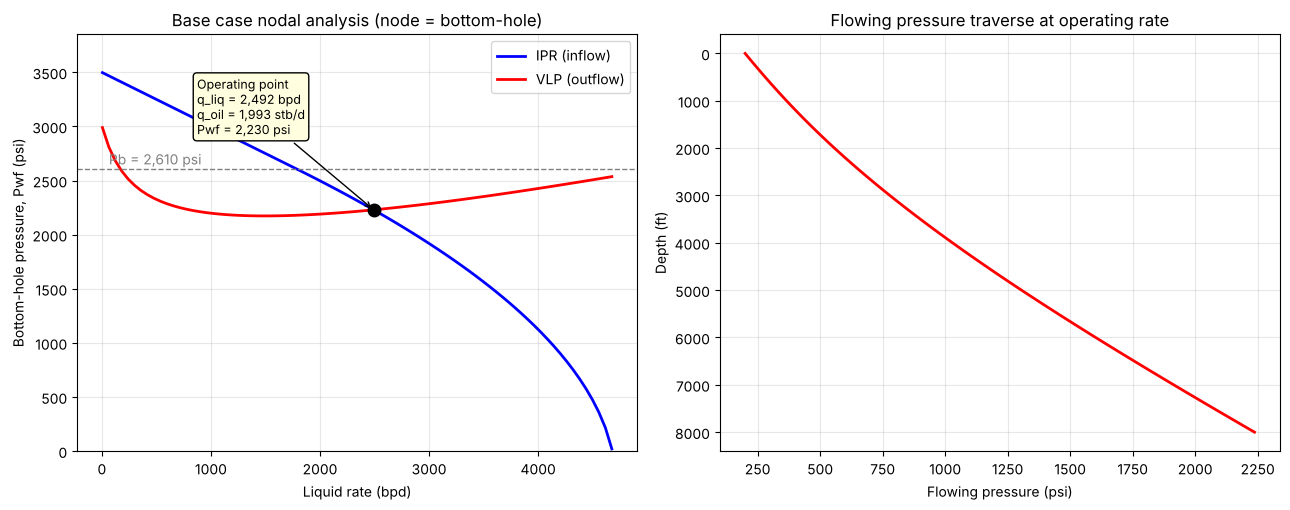

In [8]:
print(f"Bubble-point pressure : {bubble_point(BASE):,.0f} psi")
print(f"IPR open-flow (AOF)   : {ipr_qmax(BASE):,.0f} bpd")
q, qo, pwf = rates(BASE)
print(f"\nBASE CASE operating point: Q_liq = {q:,.0f} bpd | Q_oil = {qo:,.0f} stb/d | Pwf = {pwf:,.0f} psi")

fig1 = plot_base_case(BASE)
plt.show()

## 7. Sensitivity analysis

Water cut, GOR, tubing ID, reservoir pressure and wellhead pressure are each varied alone. Solid lines are VLP,
dashed lines are IPR, dots are operating points.

In [9]:
SENS = {
    "Water cut (fraction)":        ("wc",        [0.0, 0.2, 0.4, 0.6, 0.8]),
    "GOR (scf/stb)":               ("gor",       [300, 600, 900, 1200, 1500]),
    "Tubing ID (in)":              ("tubing_id", [1.995, 2.441, 2.992, 3.958, 4.892]),
    "Reservoir pressure (psi)":    ("p_res",     [2800, 3150, 3500, 3850, 4200]),
    "Wellhead pressure (psi)":     ("p_wh",      [100, 200, 400, 600, 800]),
}


def plot_sensitivities(w: Well):
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    axes = axes.ravel()
    summary = {}
    for ax, (label, (attr, vals)) in zip(axes, SENS.items()):
        cmap = plt.cm.viridis(np.linspace(0, 0.9, len(vals)))
        ops = []
        for v, c in zip(vals, cmap):
            wv = replace(w, **{attr: v})
            qmax = ipr_qmax(wv)
            qs = np.linspace(5, qmax * 0.999, 60)
            ax.plot(qs, [vlp_traverse(q, wv, 50) for q in qs], color=c, lw=1.6, label=f"{v}")
            if attr in ("p_res", "wc", "gor"):      # IPR changes
                ax.plot(qs, [ipr_pwf(q, wv) for q in qs], color=c, lw=1.0, ls="--")
            q_op, _, pwf = rates(wv)
            ops.append((v, q_op, pwf))
            if q_op > 0:
                ax.plot(q_op, pwf, "o", color=c, mec="k", ms=7, zorder=5)
        if attr not in ("p_res", "wc", "gor"):
            ax.plot(qs, [ipr_pwf(q, w) for q in qs], "k--", lw=1.5, label="IPR")
        ax.set(title=f"Effect of {label}", xlabel="Liquid rate (bpd)", ylabel="Pwf (psi)")
        ax.grid(alpha=0.3); ax.legend(fontsize=8, title="VLP:" if attr in
                                      ("p_res", "wc", "gor") else None)
        summary[label] = ops

    # 6th panel: operating liquid rate vs normalised parameter
    ax = axes[5]
    for label, ops in summary.items():
        v = np.array([o[0] for o in ops], float)
        ax.plot((v - v.min()) / (v.max() - v.min()), [o[1] for o in ops], "o-", label=label)
    ax.set(title="Operating rate vs normalised parameter", xlabel="Normalised parameter (0 = min, 1 = max)",
           ylabel="Liquid rate (bpd)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.suptitle("Sensitivity analysis (solid = VLP, dashed = IPR, dots = operating points)", fontsize=13)
    fig.tight_layout()
    return fig, summary

SENSITIVITY (value -> liquid rate bpd, Pwf psi)
  Water cut (fraction)
          0.0 ->    2,814 bpd   Pwf   2,037
          0.2 ->    2,492 bpd   Pwf   2,230
          0.4 ->    2,014 bpd   Pwf   2,491
          0.6 ->    1,296 bpd   Pwf   2,852
          0.8 ->        0 bpd   Pwf   3,500
  GOR (scf/stb)
          300 ->    1,517 bpd   Pwf   2,742
          600 ->    2,492 bpd   Pwf   2,230
          900 ->    2,522 bpd   Pwf   1,923
         1200 ->    2,672 bpd   Pwf   1,795
         1500 ->    2,739 bpd   Pwf   1,735
  Tubing ID (in)
        1.995 ->    1,749 bpd   Pwf   2,625
        2.441 ->    2,189 bpd   Pwf   2,398
        2.992 ->    2,492 bpd   Pwf   2,230
        3.958 ->    2,626 bpd   Pwf   2,151
        4.892 ->    2,563 bpd   Pwf   2,188
  Reservoir pressure (psi)
         2800 ->    1,172 bpd   Pwf   2,183
         3150 ->    1,872 bpd   Pwf   2,183
         3500 ->    2,492 bpd   Pwf   2,230
         3850 ->    3,075 bpd   Pwf   2,295
         4200 ->    3,637 bpd   P

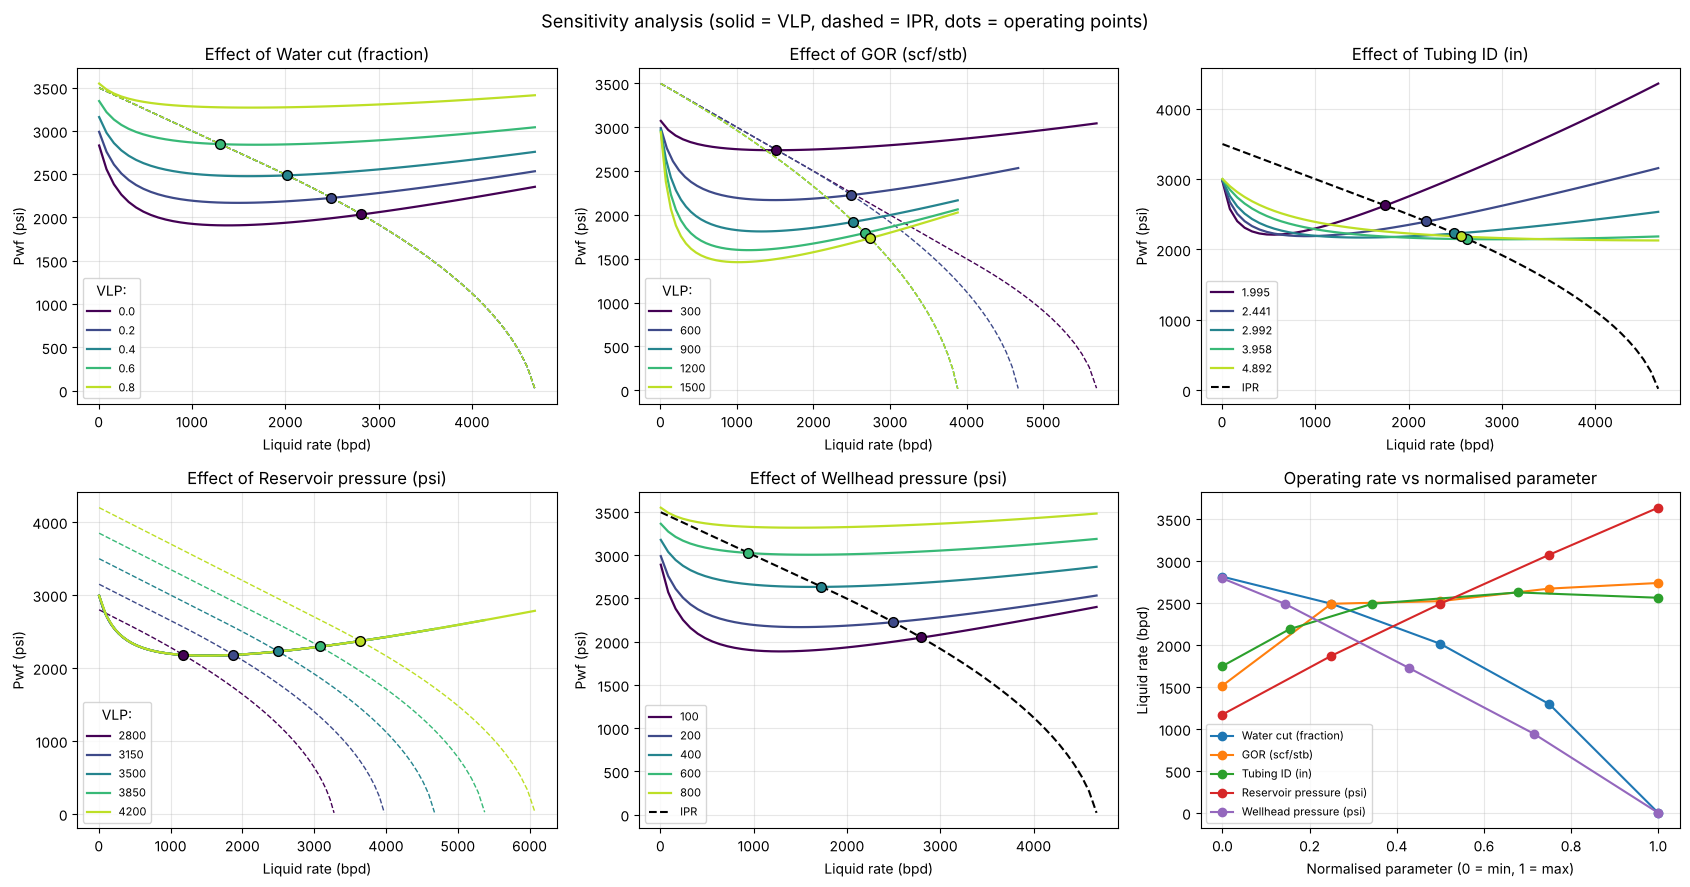

In [10]:
fig2, summary = plot_sensitivities(BASE)
print("SENSITIVITY (value -> liquid rate bpd, Pwf psi)")
for label, ops in summary.items():
    print(f"  {label}")
    for v, qq, pw in ops:
        print(f"     {v:>8} -> {qq:8,.0f} bpd   Pwf {pw:7,.0f}")
plt.show()

## 8. Bottleneck (tornado) analysis

Each parameter is moved to a low and a high value; the bar shows the resulting oil-rate swing around the base case
(green = rate rises, red = rate falls).

In [11]:
def plot_tornado(w: Well):
    """Bottleneck ID: swing in oil rate when each parameter moves to a favourable/unfavourable value."""
    cases = {
        "Water cut (0.05 / 0.50)":       [("wc", 0.05), ("wc", 0.50)],
        "GOR (400 / 1000 scf/stb)":      [("gor", 400), ("gor", 1000)],
        "Tubing ID (2.441 / 3.958 in)":  [("tubing_id", 2.441), ("tubing_id", 3.958)],
        "Reservoir P (-15% / +15%)":     [("p_res", w.p_res * 0.85), ("p_res", w.p_res * 1.15)],
        "Wellhead P (600 / 100 psi)":    [("p_wh", 600), ("p_wh", 100)],
        "Productivity index J (1 / 3)":  [("J", 1.0), ("J", 3.0)],
    }
    _, q0, _ = rates(w)
    res = []
    for name, ((a1, v1), (a2, v2)) in cases.items():
        lo = rates(replace(w, **{a1: v1}))[1]
        hi = rates(replace(w, **{a2: v2}))[1]
        res.append((name, lo, hi, abs(hi - lo)))
    res.sort(key=lambda r: r[3])

    fig, ax = plt.subplots(figsize=(10, 5.5))
    for i, (name, lo, hi, _) in enumerate(res):
        for val in (lo, hi):
            ax.barh(i, val - q0, left=q0, edgecolor="k",
                    color="seagreen" if val > q0 else "tomato")
        ax.text(max(lo, hi) + 15, i, f"{lo:,.0f} .. {hi:,.0f}", va="center", fontsize=8)
    ax.set_yticks(range(len(res))); ax.set_yticklabels([r[0] for r in res])
    ax.axvline(q0, color="k", lw=1.5)
    ax.set(xlabel="Oil rate (stb/d)",
           title=f"Bottleneck (tornado) analysis - base oil rate {q0:,.0f} stb/d\n"
                 "green = oil rate rises, red = oil rate falls")
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    return fig, res, q0

BOTTLENECK RANKING (oil-rate swing, stb/d):
  Water cut (0.05 / 0.50)            2,607 ->     844   swing  1,763
  Productivity index J (1 / 3)       1,033 ->   2,747   swing  1,714
  Wellhead P (600 / 100 psi)           755 ->   2,235   swing  1,480
  Reservoir P (-15% / +15%)          1,231 ->   2,687   swing  1,456
  GOR (400 / 1000 scf/stb)           1,529 ->   2,069   swing    540
  Tubing ID (2.441 / 3.958 in)       1,751 ->   2,101   swing    350


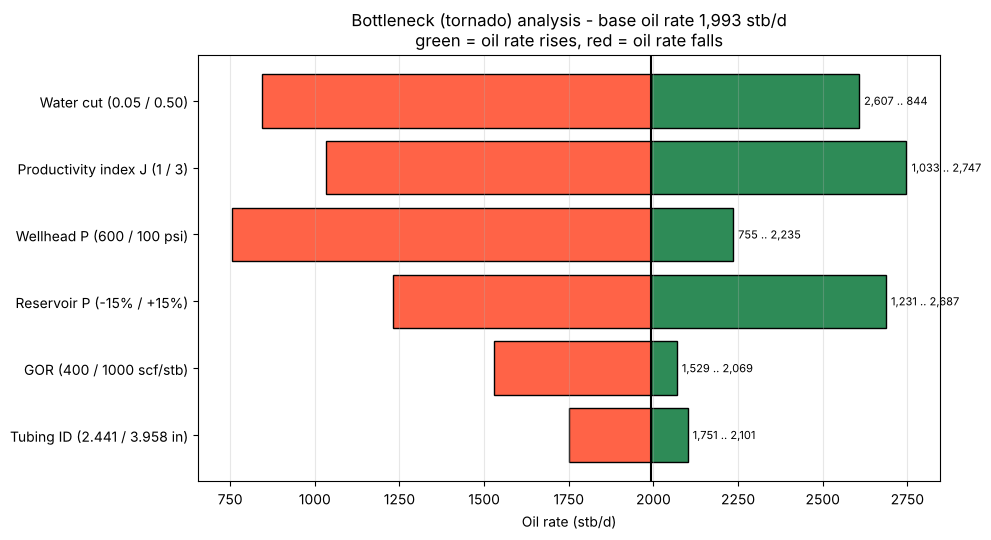

In [12]:
fig3, tor, q0 = plot_tornado(BASE)
print("BOTTLENECK RANKING (oil-rate swing, stb/d):")
for name, lo, hi, sw in reversed(tor):
    print(f"  {name:32s} {lo:7,.0f} -> {hi:7,.0f}   swing {sw:6,.0f}")
plt.show()

## 9. Conclusions

* The natural-flow operating point is where the IPR and VLP curves cross (section 6).
* Water cut and the productivity index are the largest bottlenecks, followed by wellhead pressure and
  reservoir pressure. GOR and tubing size are second-order for this well.
* Rising water cut and falling reservoir pressure push the well toward the point where natural flow stops.

**Limitations:** vertical well, single layer, steady state, standard published correlations. Tune the PVT and
VLP correlations to field data before relying on absolute rates; the ranking of parameters is more robust than
the absolute numbers. Inputs here are illustrative.